# NB26: Ensemble & Stochastic Processes
## Uncertainty Propagation through RELIC Simulations

RELIC's stochastic framework provides:
- **Parameter uncertainty**: Monte Carlo / Latin Hypercube sampling
- **Weather stochasticity**: Ornstein-Uhlenbeck temperature, Markov-Gamma precipitation
- **SDE solvers**: Euler-Maruyama for stochastic differential equations
- **Ensemble runner**: Parallel multi-member simulation management
- **Gillespie SSA**: Exact stochastic simulation for discrete reactions

**Key module**: `relic.stochastic`

---

## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below are intended to use actual RELIC functors, the actual simulator or orchestration layer, and real validation pathways rather than notebook-defined pseudo-process equations.


## Learning Goals

- Drive actual hydrology functors with RELIC stochastic weather, SDE, and SSA modules.
- Inspect ensemble spread, probabilistic scores, and stochastic forcing diagnostics over a realistic forecast window.
- Distinguish physically meaningful spread from sampling noise or plotting artifacts.


In [1]:
import asyncio
import os
import sys
from pathlib import Path

if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"


DEFAULT_PROJECT_ROOT = Path(os.environ.get("RELIC_PROJECT_ROOT", os.getcwd()))


def locate_project_root() -> Path:
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents, DEFAULT_PROJECT_ROOT]
    for candidate in candidates:
        if (candidate / "relic").is_dir() and (candidate / "docs" / "source" / "architecture_overview.md").is_file():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate RELIC project root. Set RELIC_PROJECT_ROOT if needed.")


PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import torch

from relic.stochastic.distributions import DistributionSpec, DistributionType, ParameterDistribution
from relic.stochastic.sde_solver import EulerMaruyamaSolver, SDEParameters
from relic.stochastic.weather_generator import WeatherGenerator, TemperatureParameters, PrecipitationParameters
from relic.stochastic.gillespie import GillespieSSA, Reaction, ReactionSystem
from relic.stochastic.validation import CRPSValidator
from relic.scientific.hydrosphere.evapotranspiration.penman_monteith import PenmanMonteithET
from relic.scientific.hydrosphere.soil_moisture.bucket import BucketSoilMoisture

N_ENSEMBLE = 24
WEATHER_DAYS = 2
WEATHER_STEPS = 96
BUCKET_DT_SECONDS = 1800.0

print("[OK] Stochastic modules loaded")
print(f"  WeatherGenerator: {WeatherGenerator.__module__}")
print(f"  EulerMaruyamaSolver: {EulerMaruyamaSolver.__module__}")
print(f"  GillespieSSA: {GillespieSSA.__module__}")
print(f"  PenmanMonteithET: {PenmanMonteithET.__module__}")
print(f"  BucketSoilMoisture: {BucketSoilMoisture.__module__}")
print(f"  Ensemble size: {N_ENSEMBLE}")
print(f"  Bucket dt [s]: {BUCKET_DT_SECONDS}")
print(f"  Forecast horizon [h]: {WEATHER_STEPS * BUCKET_DT_SECONDS / 3600.0:.1f}")


[OK] Stochastic modules loaded
  WeatherGenerator: relic.stochastic.weather_generator
  EulerMaruyamaSolver: relic.stochastic.sde_solver
  GillespieSSA: relic.stochastic.gillespie
  PenmanMonteithET: relic.scientific.hydrosphere.evapotranspiration.penman_monteith
  BucketSoilMoisture: relic.scientific.hydrosphere.soil_moisture.bucket
  Ensemble size: 24
  Bucket dt [s]: 1800.0
  Forecast horizon [h]: 48.0


## 1. Parameter Distributions

Define uncertainty distributions for model parameters using
`ParameterDistribution`. These feed into ensemble runs.

$$\theta \sim \mathcal{N}(\mu, \sigma^2) \quad \text{or} \quad \theta \sim \text{Uniform}(a, b)$$


In [2]:
# References:
# - Beven and Binley (1992) on hydrologic parameter uncertainty.
# - Gelman et al. (2013) on probabilistic parameter sampling.
# - RELIC implementation: relic.stochastic.distributions.ParameterDistribution.
# Mathematical expression:
# - theta0_i ~ Normal(mu_theta, sigma_theta), clipped to physical bounds.
# - s_r_i ~ Normal(mu_r, sigma_r), clipped to physical bounds.
# Parameter meanings:
# - initial_soil_moisture: initial bucket water content [m3 m-3].
# - surface_resistance_scale: multiplicative factor on Penman-Monteith surface resistance [1].
# Units:
# - Soil moisture uses m3 m-3 and the resistance scale is dimensionless.
# Domain/constraints:
# - Samples are clipped to the declared physical bounds in each DistributionSpec.
# Sign convention:
# - Larger resistance scale means stronger resistance and normally lower evapotranspiration.

print("=== Parameter Distribution Framework ===")

initial_soil_moisture_dist = DistributionSpec(
    dist_type=DistributionType.NORMAL,
    params={"loc": 0.28, "scale": 0.015},
    bounds=(0.20, 0.40),
    log_scale=False,
)
print(f"  Initial soil moisture: {initial_soil_moisture_dist.dist_type.name}")
print(f"    params: {initial_soil_moisture_dist.params}")
print(f"    bounds: {initial_soil_moisture_dist.bounds}")

surface_resistance_scale_dist = DistributionSpec(
    dist_type=DistributionType.NORMAL,
    params={"loc": 1.00, "scale": 0.10},
    bounds=(0.70, 1.30),
)
print(
    "  Surface resistance scale: "
    f"{surface_resistance_scale_dist.dist_type.name}, loc={surface_resistance_scale_dist.params['loc']}"
)

param_dist = ParameterDistribution(
    parameter_specs={
        "initial_soil_moisture": initial_soil_moisture_dist,
        "surface_resistance_scale": surface_resistance_scale_dist,
    }
)
print(f"\nParameterDistribution created with {len(param_dist.parameter_specs)} parameters")

param_sample_result = param_dist.sample(
    input_state=torch.zeros(1, dtype=torch.float32),
    num_samples=N_ENSEMBLE,
    seed=21,
)
print(f"  Generated {N_ENSEMBLE} ensemble members")
print(f"  Result keys: {list(param_sample_result.keys())}")
for key, vals in param_sample_result.items():
    if isinstance(vals, torch.Tensor):
        vals_float = vals.float().reshape(-1)
        print(
            f"    {key}: shape={vals.shape}, mean={vals_float.mean():.4f}, std={vals_float.std():.4f}, "
            f"min={vals_float.min():.4f}, max={vals_float.max():.4f}"
        )

print("[OK] Parameter distribution tutorial complete")


=== Parameter Distribution Framework ===
  Initial soil moisture: NORMAL
    params: {'loc': 0.28, 'scale': 0.015}
    bounds: (0.2, 0.4)
  Surface resistance scale: NORMAL, loc=1.0

ParameterDistribution created with 2 parameters
  Generated 24 ensemble members
  Result keys: ['initial_soil_moisture', 'surface_resistance_scale']
    initial_soil_moisture: shape=torch.Size([24, 1]), mean=0.2796, std=0.0157, min=0.2471, max=0.3094
    surface_resistance_scale: shape=torch.Size([24, 1]), mean=1.0436, std=0.1007, min=0.8548, max=1.2058
[OK] Parameter distribution tutorial complete


## 2. Stochastic Weather Generator

Generate stochastic meteorological forcing with actual RELIC weather-process
modules. The trajectories are sampled, but every sample comes from the
implemented Ornstein-Uhlenbeck temperature process and Markov precipitation
process inside `WeatherGenerator`, not from hand-drawn curves. The combined
generator advances one **day** per sample, using the exact OU transition.
Two daily temperature samples and precipitation rates are mapped to the 48-hour
hydrology window by `TemporalDisaggregator` with explicit bounds and uniform
piecewise-constant reconstruction. This is an explicit daily-hold assumption,
not a subdaily weather model; total precipitation is checked before and after.
The wet-day temperature offset is 0.25 K, not a correlation coefficient.
WeatherGenerator does not produce relative humidity.

$$dT = \theta(\mu - T)dt + \sigma dW_t$$

Reference: Uhlenbeck & Ornstein (1930), Physical Review; Kilsby et al. (2007), Journal of Hydrology


In [3]:
# References:
# - Richardson (1981) stochastic weather generator concepts.
# - Elshamy et al. (2006) rainfall weather generator evaluation.
# - RELIC implementation: relic.stochastic.weather_generator.WeatherGenerator.
# Mathematical expression:
# - T_next = mu + (T - mu) exp(-alpha dt) + sigma sqrt((1-exp(-2 alpha dt))/(2 alpha)) xi.
# - WeatherGenerator advances one day; the temporal owner holds each daily mean/rate over 48 half-hours.
# - P(wet_t | wet_{t-1}) from Markov transition probabilities.
# Parameter meanings:
# - air_temperature: generated temperature trajectory [K].
# - precipitation_flux: generated precipitation flux [kg m-2 s-1].
# - wet_day_temperature_offset: explicit additive wet-day temperature offset [K].
# Units:
# - Temperature uses K, precipitation uses kg m-2 s-1, and the generator time step is one day.
# Domain/constraints:
# - Each call owns its seed and returns finite trajectories for the declared step count.
# Sign convention:
# - Positive precipitation flux adds water to the land surface.

print("=== Weather Generator ===")
from dataclasses import replace
from relic.utils.time_constants import SECONDS_PER_DAY
from relic.coupling.scales.types import SpatialQuantityBasis
from relic.coupling.scales.temporal.types import TemporalConfig, TemporalSemantics, ScalingDirection, ConservationLevel
from relic.coupling.scales.temporal.disaggregator import TemporalDisaggregator, DisaggregationConfig, DisaggregationMethod

temperature_parameters = replace(
    TemperatureParameters.from_parameter_manager(), wet_day_temperature_offset=0.25,
)
weather_generator = WeatherGenerator(
    temperature_parameters, PrecipitationParameters.from_parameter_manager(),
)
daily_weather_result = weather_generator.sample(
    input_state=torch.tensor(289.15, dtype=torch.float32),
    num_samples=N_ENSEMBLE,
    num_steps=WEATHER_DAYS,
    seed=42,
)
daily_truth_weather_result = weather_generator.sample(
    input_state=torch.tensor(289.15, dtype=torch.float32),
    num_samples=1,
    num_steps=WEATHER_DAYS,
    seed=142,
)

# References: RELIC TemporalDisaggregator; CF temporal interval-mean/rate semantics.
# Mathematical expression: x_halfhour = x_day on its daily support; sum(q_h dt_h) = sum(q_d dt_d).
# Parameter meanings: daily_bounds and forcing_bounds declare the two-day support in seconds.
# Units: temperature [K]; precipitation [kg m-2 s-1]; interval measures [K s] or [kg m-2].
# Domain/constraints: full coverage, no extrapolation; uniform holds do not reconstruct subdaily weather.
# Sign convention: precipitation is downward positive; the same daily water amount is distributed once.
day_seconds = float(SECONDS_PER_DAY)
daily_edges = torch.arange(WEATHER_DAYS + 1, dtype=torch.float64) * day_seconds
daily_bounds = torch.stack((daily_edges[:-1], daily_edges[1:]), dim=1)
forcing_edges = torch.arange(WEATHER_STEPS + 1, dtype=torch.float64) * BUCKET_DT_SECONDS
forcing_bounds = torch.stack((forcing_edges[:-1], forcing_edges[1:]), dim=1)
assert forcing_edges[-1] == daily_edges[-1]

def hold_daily_weather(daily):
    result = {}
    for key, units, measure, basis, semantics in [
        ("air_temperature", "K", "K s", SpatialQuantityBasis.INTENSIVE, TemporalSemantics.INTERVAL_MEAN),
        ("precipitation_flux", "kg m-2 s-1", "kg m-2", SpatialQuantityBasis.AREA_DENSITY, TemporalSemantics.RATE),
    ]:
        mapper = TemporalDisaggregator(
            TemporalConfig(
                source_frequency="daily", target_frequency="sub-hourly",
                direction=ScalingDirection.DOWNSCALE, spatial_basis=basis,
                temporal_semantics=semantics, conservation_level=ConservationLevel.NONE,
                device=torch.device("cpu"),
            ),
            DisaggregationConfig(method=DisaggregationMethod.UNIFORM, time_dim=-1),
        )
        mapped = mapper.disaggregate(
            daily[key], daily_bounds.mean(dim=1), forcing_bounds.mean(dim=1),
            variable_name=key, standard_name=key, units=units, target_units=units,
            measure_units=measure, integration_time_unit="s",
            time_units="seconds since 2001-01-01 00:00:00", calendar="noleap",
            source_bounds=daily_bounds, target_bounds=forcing_bounds,
        )
        result[key] = mapped.data
    daily_amount = daily["precipitation_flux"].to(torch.float64).sum(dim=-1) * day_seconds
    forcing_amount = result["precipitation_flux"].to(torch.float64).sum(dim=-1) * BUCKET_DT_SECONDS
    assert torch.allclose(daily_amount, forcing_amount, rtol=1.0e-6, atol=1.0e-10)
    assert result["air_temperature"].shape[-1] == WEATHER_STEPS
    print(f"  Daily-to-half-hour precipitation residual [kg m-2]: {float((daily_amount-forcing_amount).abs().max()):.3e}")
    return result

weather_result = hold_daily_weather(daily_weather_result)
truth_weather_result = hold_daily_weather(daily_truth_weather_result)

print(f"  Result keys: {list(weather_result.keys())}")
print(f"  air_temperature shape: {weather_result['air_temperature'].shape}")
print(f"  precipitation_flux shape: {weather_result['precipitation_flux'].shape}")
print(f"  temperature range [K]: {float(weather_result['air_temperature'].min()):.2f} to {float(weather_result['air_temperature'].max()):.2f}")
print(f"  wet-step fraction: {float((weather_result['precipitation_flux'] > 0.0).float().mean()):.3f}")
print(f"  wet-day temperature offset [K]: {temperature_parameters.wet_day_temperature_offset:.3f}")
print("  No humidity is generated; the hydrology experiment declares its VPD boundary separately.")
print("[OK] WeatherGenerator sampling complete")


=== Weather Generator ===
  Daily-to-half-hour precipitation residual [kg m-2]: 0.000e+00
  Daily-to-half-hour precipitation residual [kg m-2]: 0.000e+00
  Result keys: ['air_temperature', 'precipitation_flux']
  air_temperature shape: torch.Size([24, 96])
  precipitation_flux shape: torch.Size([24, 96])
  temperature range [K]: 284.85 to 294.18
  wet-step fraction: 0.104
  wet-day temperature offset [K]: 0.250
  No humidity is generated; the hydrology experiment declares its VPD boundary separately.
[OK] WeatherGenerator sampling complete


## 3. SDE Solver (Euler-Maruyama)

Solve stochastic differential equations for processes with noise.
RELIC uses the Euler-Maruyama method:

$$X_{n+1} = X_n + f(X_n)\Delta t + g(X_n)\sqrt{\Delta t}\,\xi_n$$

where $\xi_n \sim \mathcal{N}(0,1)$.


In [4]:
# References:
# - Kloeden and Platen (1992) numerical solution of SDEs.
# - Oksendal (2003) stochastic differential equations.
# - RELIC implementation: EulerMaruyamaSolver.
# Mathematical expression:
# - X_{n+1} = X_n + a(X_n, t_n) * dt + b(X_n, t_n) * sqrt(dt) * xi_n
# Parameter meanings:
# - solution: simulated state trajectories.
# - drift_history: deterministic increment term.
# - diffusion_history: stochastic increment coefficient.
# Units:
# - X is dimensionless, time uses the declared solver unit, a has X time-1, and b has X time-1/2.
# Domain/constraints:
# - The fixed-step Euler-Maruyama contract requires explicit finite drift and diffusion operators.
# Sign convention:
# - Negative drift removes state; positive Wiener increments increase state when b is positive.

print("=== Euler-Maruyama SDE Solver ===")
SDE_DT = 0.05
SDE_STEPS = 80
DECOMPOSITION_RATE = 0.08
NOISE_INTENSITY = 0.05


def decomposition_drift(x: torch.Tensor, t: torch.Tensor, **kwargs) -> torch.Tensor:
    return -kwargs["decomposition_rate"] * x


def multiplicative_diffusion(x: torch.Tensor, t: torch.Tensor, **kwargs) -> torch.Tensor:
    return kwargs["noise_intensity"] * x


sde_solver = EulerMaruyamaSolver(
    SDEParameters(dt=SDE_DT, method='euler_maruyama', diffusion_structure='diagonal'),
    drift_func=decomposition_drift,
    diffusion_func=multiplicative_diffusion,
)
sde_result = sde_solver.sample(
    input_state=torch.tensor(1.0, dtype=torch.float32),
    num_samples=N_ENSEMBLE,
    num_steps=SDE_STEPS,
    seed=42,
    decomposition_rate=DECOMPOSITION_RATE,
    noise_intensity=NOISE_INTENSITY,
)
sde_replay = sde_solver.sample(
    input_state=torch.tensor(1.0, dtype=torch.float32),
    num_samples=N_ENSEMBLE,
    num_steps=SDE_STEPS,
    seed=42,
    decomposition_rate=DECOMPOSITION_RATE,
    noise_intensity=NOISE_INTENSITY,
)
deterministic_solver = EulerMaruyamaSolver(
    SDEParameters(dt=SDE_DT, method='euler_maruyama', diffusion_structure='diagonal'),
    drift_func=decomposition_drift,
    diffusion_func=lambda x, t, **kwargs: torch.zeros_like(x),
)
deterministic_result = deterministic_solver.sample(
    input_state=torch.tensor(1.0, dtype=torch.float32),
    num_samples=1,
    num_steps=SDE_STEPS,
    seed=7,
    decomposition_rate=DECOMPOSITION_RATE,
)
expected_discrete_final = (1.0 - DECOMPOSITION_RATE * SDE_DT) ** SDE_STEPS
deterministic_final = float(deterministic_result["solution"][0, -1].item())
deterministic_oracle_error = abs(deterministic_final - expected_discrete_final)
replay_max_abs_error = float(torch.max(torch.abs(sde_result["solution"] - sde_replay["solution"])).item())
assert deterministic_oracle_error < 1.0e-6
assert replay_max_abs_error == 0.0
print(f"  Result keys: {list(sde_result.keys())}")
print(f"  solution shape: {sde_result['solution'].shape}")
print(f"  drift_history shape: {sde_result['drift_history'].shape}")
print(f"  diffusion_history shape: {sde_result['diffusion_history'].shape}")
print(f"  solution range: {float(sde_result['solution'].min()):.3f} to {float(sde_result['solution'].max()):.3f}")
print(f"  deterministic oracle error: {deterministic_oracle_error:.3e}")
print(f"  seeded replay max error: {replay_max_abs_error:.3e}")
print("[OK] Euler-Maruyama sampling complete")


=== Euler-Maruyama SDE Solver ===
  Result keys: ['solution', 'time', 'dt_used', 'drift_history', 'diffusion_history', 'seed']
  solution shape: torch.Size([24, 81])
  drift_history shape: torch.Size([24, 80])
  diffusion_history shape: torch.Size([24, 80])
  solution range: 0.545 to 1.051
  deterministic oracle error: 1.747e-07
  seeded replay max error: 0.000e+00
[OK] Euler-Maruyama sampling complete


## 4. Gillespie Stochastic Simulation Algorithm

For discrete biochemical reactions (e.g., enzyme kinetics, litter decomposition
at molecular scale), RELIC provides the exact Gillespie SSA.

Reference: Gillespie (1977), J. Phys. Chem. 81:2340-2361


In [5]:
# References:
# - Gillespie (1976, 1977) exact stochastic simulation of coupled reactions.
# - RELIC implementation: relic.stochastic.gillespie.GillespieSSA.
# Mathematical expression:
# - tau = -ln(r1) / a0 where a0 is the total propensity.
# - Choose reaction k such that sum_{j<=k} a_j >= r2 * a0.
# Parameter meanings:
# - population: generic discrete state used only to demonstrate the jump-process contract.
# - birth_rate: zero-order event intensity [time-1].
# - death_rate: first-order event intensity [time-1].
# Units:
# - Population is a count and reaction times use the solver time unit.
# Domain/constraints:
# - Species counts remain non-negative integers and propensities remain finite and non-negative.
# Sign convention:
# - Birth adds one population unit and death removes one.
# Note:
# - This cell demonstrates the exact jump-process solver contract.
# - It is not presented as a calibrated ecosystem parameterization.

print("=== Gillespie Stochastic Simulation Algorithm ===")

canonical_jump_system = ReactionSystem(
    species=["population"],
    reactions=[
        Reaction(
            name="birth",
            reactants={},
            products={"population": 1},
            rate_constant=2.5,
        ),
        Reaction(
            name="death",
            reactants={"population": 1},
            products={},
            rate_constant=0.12,
        ),
    ],
    initial_state={"population": 15},
)

ssa = GillespieSSA(canonical_jump_system)
ssa_result = ssa.sample(
    input_state=torch.tensor([15.0], dtype=torch.float32),
    num_samples=5,
    seed=42,
    final_time=8.0,
    max_reactions=400,
)
print(f"  Result keys: {list(ssa_result.keys())}")
print(f"  Populations shape: {ssa_result['populations'].shape}")
traj_lens = ssa_result['trajectory_lengths']
print(f"  Trajectory lengths: {traj_lens.tolist()}")
final_pops = []
for sample_idx in range(ssa_result['populations'].shape[0]):
    final_idx = int(traj_lens[sample_idx].item()) - 1
    final_pops.append(int(ssa_result['populations'][sample_idx, final_idx, 0].item()))
print(f"  Final population range: {min(final_pops)} to {max(final_pops)}")
print("[OK] Gillespie SSA contract demonstration complete")


=== Gillespie Stochastic Simulation Algorithm ===
  Result keys: ['populations', 'times', 'reactions', 'propensities', 'trajectory_lengths', 'reached_max_reactions', 'final_time', 'seed', 'species_names', 'reaction_names', 'stoichiometric_matrix']
  Populations shape: torch.Size([5, 401, 1])
  Trajectory lengths: [45, 54, 27, 41, 34]
  Final population range: 15 to 32
[OK] Gillespie SSA contract demonstration complete


## 5. Stochastic Forcing Propagation Through Scientific Functors and CRPS Validation

Propagate RELIC stochastic forcing through the actual
`WeatherGenerator -> PenmanMonteithET -> BucketSoilMoisture` chain. This keeps
both atmospheric demand and soil-moisture update on real RELIC functors while
using a suitable half-hour time step for the fast hydrology response.
An explicitly prescribed constant VPD of 1000 Pa is a teaching boundary input;
it is not a humidity model or a WeatherGenerator output. Kernel calls advance
only the local tutorial trajectory; they do not certify simulator governance.

$$ET_n = \mathrm{PenmanMonteithET}(\mathrm{weather}_n), \qquad \theta_{n+1} = \mathrm{BucketSoilMoisture}(\theta_n, P_n, ET_n, \Delta t)$$

Reference: Monteith (1965), Quarterly Journal of the Royal Meteorological Society; Manabe (1969), Monthly Weather Review; Gneiting & Raftery (2007), JASA


=== Stochastic Propagation Through PenmanMonteithET and BucketSoilMoisture ===


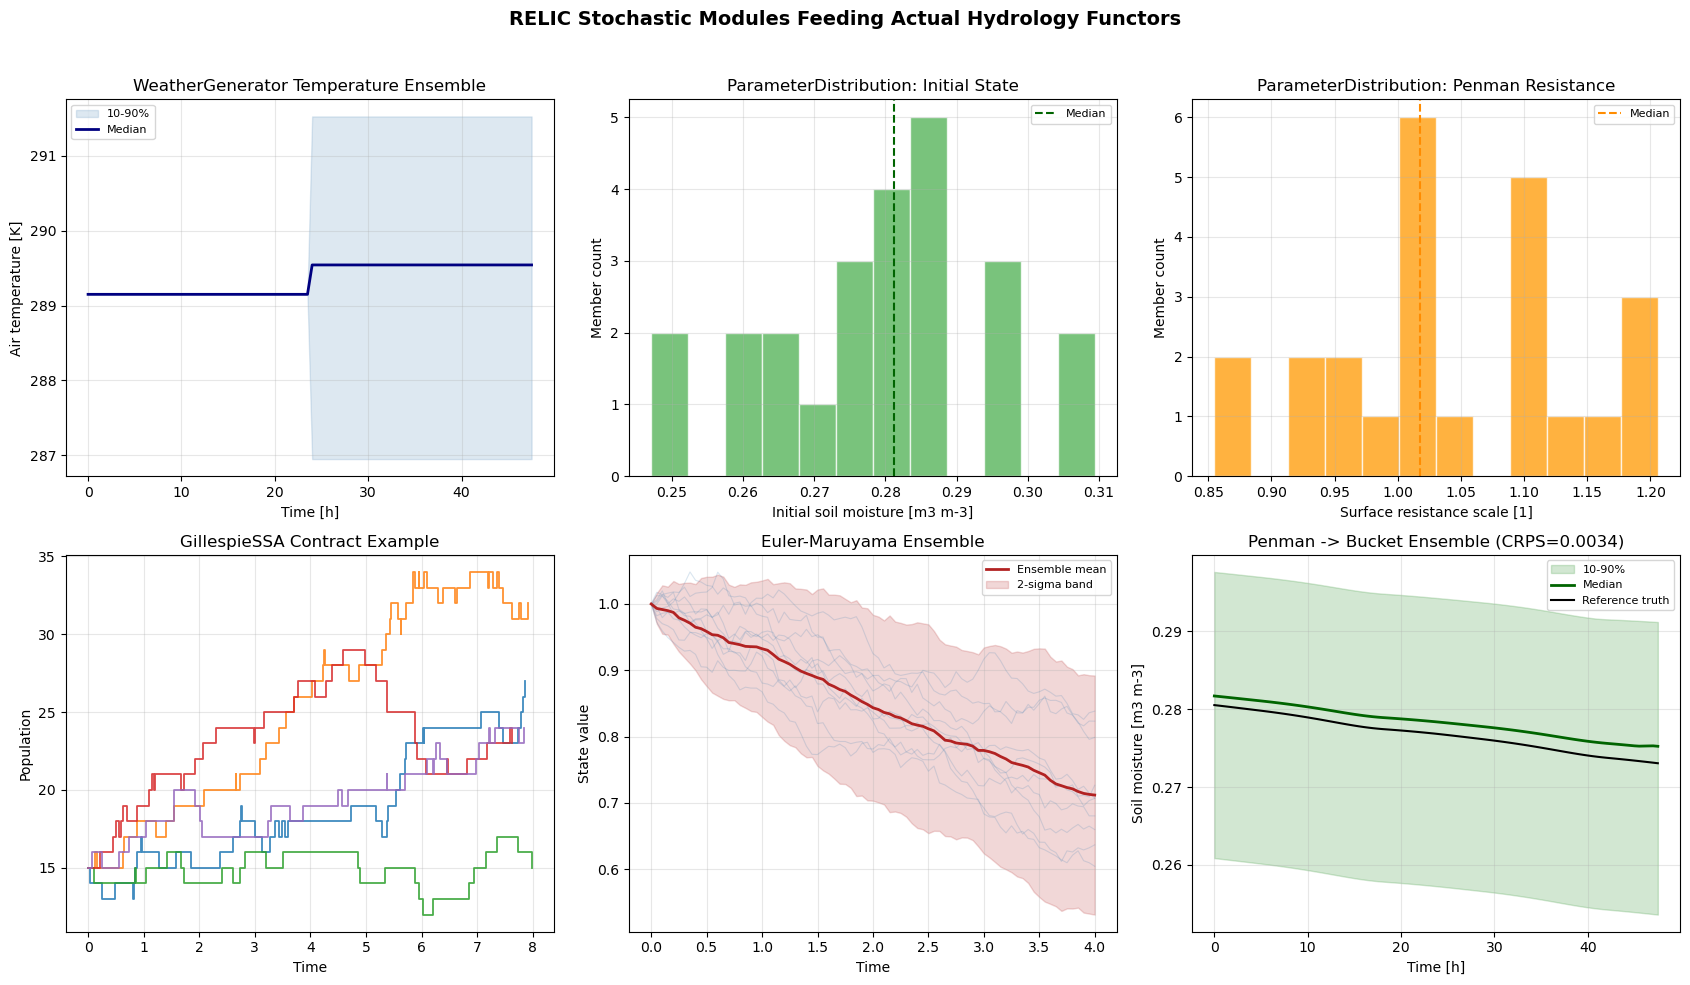

  Penman ET range: 2.197157e-05 to 6.286157e-05
  Bucket truth range: 0.2731 to 0.2805
  Bucket ensemble spread at final step: 0.0147
  CRPS mean: 0.003400
[OK] Stochastic propagation and visualization generated


In [6]:
# References:
# - Monteith (1965) Penman-Monteith evapotranspiration.
# - Manabe (1969) bucket soil-moisture balance.
# - Gneiting and Raftery (2007) CRPS for probabilistic forecasts.
# - RELIC implementations: WeatherGenerator, ParameterDistribution, PenmanMonteithET, BucketSoilMoisture, CRPSValidator.
# Mathematical expression:
# - ET_n = PenmanMonteithET(weather_n, resistance_n).
# - theta_(n+1) = Bucket(theta_n, P_n, ET_n, dt).
# - CRPS = (1 / M) * sum_i |x_i - y| - (1 / (2 M^2)) * sum_i sum_j |x_i - x_j|.
# Parameter meanings:
# - initial_soil_moisture: initial volumetric water content [m3 m-3].
# - surface_resistance_scale: multiplicative factor on Penman-Monteith surface resistance [1].
# - precipitation_flux: stochastic forcing from WeatherGenerator [kg m-2 s-1].
# - evapotranspiration_flux: atmospheric demand computed by PenmanMonteithET [kg m-2 s-1].
# - soil_moisture: bucket-model state trajectory [m3 m-3].
# Units:
# - Fluxes use kg m-2 s-1, time uses s, and soil moisture uses m3 m-3.
# Domain/constraints:
# - Each member uses the same forcing horizon; CRPS compares aligned member and truth times.
# Sign convention:
# - Precipitation adds bucket water, while positive evapotranspiration removes it.

import matplotlib.pyplot as plt
from IPython.display import display

print("=== Stochastic Propagation Through PenmanMonteithET and BucketSoilMoisture ===")

bucket_functor = BucketSoilMoisture(name="nb26_bucket_stochastic")
penman_functor = PenmanMonteithET(name="nb26_penman_stochastic", config={"canopy_resistance_source": "state"})
crps_validator = CRPSValidator(decompose=True)
weather_time = torch.arange(WEATHER_STEPS, dtype=torch.float32)
forecast_hours = weather_time * (BUCKET_DT_SECONDS / 3600.0)
radiation_phase = 2.0 * torch.pi * forecast_hours / 24.0
net_radiation_series = torch.clamp(
    55.0 + 205.0 * torch.sin(radiation_phase - 0.5 * torch.pi) + 28.0 * torch.sin(2.0 * radiation_phase),
    min=18.0,
)
wind_speed_series = torch.clamp(
    1.5 + 0.7 * torch.sin(radiation_phase + 0.35) + 0.25 * torch.cos(0.5 * radiation_phase),
    min=0.5,
)


def run_penman_bucket_trajectory(
    initial_soil_moisture: torch.Tensor,
    air_temperature: torch.Tensor,
    precipitation_flux: torch.Tensor,
    surface_resistance_scale: torch.Tensor,
) -> tuple[torch.Tensor, torch.Tensor]:
    theta = initial_soil_moisture.reshape(()).detach().clone()
    theta_series = []
    et_series = []
    for step_idx in range(WEATHER_STEPS):
        penman_outputs = penman_functor.forward(
            {
                "air_temperature": air_temperature[step_idx],
                # Explicit teaching boundary, not generated by WeatherGenerator.
                "vapor_pressure_deficit": torch.tensor(1000.0, dtype=torch.float32),
                "precipitation_flux": precipitation_flux[step_idx],
                "net_radiation": net_radiation_series[step_idx],
                "wind_speed": wind_speed_series[step_idx],
                "atmospheric_pressure": torch.tensor(101325.0, dtype=torch.float32),
                "surface_resistance": torch.tensor(140.0, dtype=torch.float32) * surface_resistance_scale.reshape(()),
                "canopy_storage": torch.tensor(0.0, dtype=torch.float32),
            },
            time=float(step_idx) * BUCKET_DT_SECONDS,
            dt=BUCKET_DT_SECONDS,
        )
        et_flux = penman_outputs["evapotranspiration_flux"].value.detach().reshape(())
        soil_outputs = bucket_functor.forward(
            {
                "soil_moisture": theta,
                "precipitation_flux": precipitation_flux[step_idx],
                "evapotranspiration_flux": et_flux,
            },
            time=float(step_idx) * BUCKET_DT_SECONDS,
            dt=BUCKET_DT_SECONDS,
        )
        theta = soil_outputs["soil_moisture"].value.detach().reshape(())
        theta_series.append(theta)
        et_series.append(et_flux)
    return torch.stack(theta_series), torch.stack(et_series)


truth_param_result = param_dist.sample(
    input_state=torch.zeros(1, dtype=torch.float32),
    num_samples=1,
    seed=314,
)
soil_truth, et_truth = run_penman_bucket_trajectory(
    truth_param_result["initial_soil_moisture"][0],
    truth_weather_result["air_temperature"][0],
    truth_weather_result["precipitation_flux"][0],
    truth_param_result["surface_resistance_scale"][0],
)
soil_ensemble_members = []
et_ensemble_members = []
for member_idx in range(N_ENSEMBLE):
    soil_member, et_member = run_penman_bucket_trajectory(
        param_sample_result["initial_soil_moisture"][member_idx],
        weather_result["air_temperature"][member_idx],
        weather_result["precipitation_flux"][member_idx],
        param_sample_result["surface_resistance_scale"][member_idx],
    )
    soil_ensemble_members.append(soil_member)
    et_ensemble_members.append(et_member)
soil_ensemble = torch.stack(soil_ensemble_members)
et_ensemble = torch.stack(et_ensemble_members)
soil_prediction_matrix = soil_ensemble.transpose(0, 1).detach()
soil_observations = soil_truth.detach()
soil_crps_result = crps_validator.compute_score(soil_observations, soil_prediction_matrix)

weather_p10 = torch.quantile(weather_result["air_temperature"], 0.10, dim=0)
weather_p50 = torch.quantile(weather_result["air_temperature"], 0.50, dim=0)
weather_p90 = torch.quantile(weather_result["air_temperature"], 0.90, dim=0)

soil_time_hours = torch.arange(WEATHER_STEPS, dtype=torch.float32) * (BUCKET_DT_SECONDS / 3600.0)
soil_q10 = torch.quantile(soil_ensemble, 0.10, dim=0)
soil_q50 = torch.quantile(soil_ensemble, 0.50, dim=0)
soil_q90 = torch.quantile(soil_ensemble, 0.90, dim=0)

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

ax = axes[0, 0]
ax.fill_between(forecast_hours.tolist(), weather_p10.tolist(), weather_p90.tolist(), alpha=0.18, color="steelblue", label="10-90%")
ax.plot(forecast_hours.tolist(), weather_p50.tolist(), color="navy", linewidth=2.0, label="Median")
ax.set_xlabel("Time [h]")
ax.set_ylabel("Air temperature [K]")
ax.set_title("WeatherGenerator Temperature Ensemble")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

ax = axes[0, 1]
initial_theta_samples = param_sample_result["initial_soil_moisture"].float().reshape(-1)
ax.hist(initial_theta_samples.tolist(), bins=12, color="#4CAF50", alpha=0.75, edgecolor="white")
ax.axvline(float(initial_theta_samples.median()), color="darkgreen", linestyle="--", linewidth=1.5, label="Median")
ax.set_xlabel("Initial soil moisture [m3 m-3]")
ax.set_ylabel("Member count")
ax.set_title("ParameterDistribution: Initial State")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

ax = axes[0, 2]
surface_resistance_scale_samples = param_sample_result["surface_resistance_scale"].float().reshape(-1)
ax.hist(surface_resistance_scale_samples.tolist(), bins=12, color="#FF9800", alpha=0.75, edgecolor="white")
ax.axvline(float(surface_resistance_scale_samples.median()), color="darkorange", linestyle="--", linewidth=1.5, label="Median")
ax.set_xlabel("Surface resistance scale [1]")
ax.set_ylabel("Member count")
ax.set_title("ParameterDistribution: Penman Resistance")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

ax = axes[1, 0]
for sample_idx in range(ssa_result["populations"].shape[0]):
    traj_len = int(ssa_result["trajectory_lengths"][sample_idx].item())
    ax.step(
        ssa_result["times"][sample_idx, :traj_len].tolist(),
        ssa_result["populations"][sample_idx, :traj_len, 0].tolist(),
        where="post",
        linewidth=1.3,
        alpha=0.85,
    )
ax.set_xlabel("Time")
ax.set_ylabel("Population")
ax.set_title("GillespieSSA Contract Example")
ax.grid(True, alpha=0.3)

ax = axes[1, 1]
for sample_idx in range(min(10, sde_result["solution"].shape[0])):
    ax.plot(sde_result["time"].tolist(), sde_result["solution"][sample_idx].tolist(), alpha=0.20, linewidth=0.8, color="steelblue")
sde_mean = sde_result["solution"].mean(dim=0)
sde_std = sde_result["solution"].std(dim=0)
ax.plot(sde_result["time"].tolist(), sde_mean.tolist(), color="firebrick", linewidth=2.0, label="Ensemble mean")
ax.fill_between(
    sde_result["time"].tolist(),
    (sde_mean - 2.0 * sde_std).tolist(),
    (sde_mean + 2.0 * sde_std).tolist(),
    alpha=0.18,
    color="firebrick",
    label="2-sigma band",
)
ax.set_xlabel("Time")
ax.set_ylabel("State value")
ax.set_title("Euler-Maruyama Ensemble")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

ax = axes[1, 2]
ax.fill_between(soil_time_hours.tolist(), soil_q10.tolist(), soil_q90.tolist(), alpha=0.20, color="forestgreen", label="10-90%")
ax.plot(soil_time_hours.tolist(), soil_q50.tolist(), color="darkgreen", linewidth=2.0, label="Median")
ax.plot(soil_time_hours.tolist(), soil_truth.tolist(), color="black", linewidth=1.5, label="Reference truth")
ax.set_xlabel("Time [h]")
ax.set_ylabel("Soil moisture [m3 m-3]")
ax.set_title(f"Penman -> Bucket Ensemble (CRPS={soil_crps_result['crps_mean']:.4f})")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.suptitle("RELIC Stochastic Modules Feeding Actual Hydrology Functors", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0.0, 0.0, 1.0, 0.96])
display(plt.gcf())
plt.close(plt.gcf())

stochastic_validation_summary = {
    "weather_temp_range_K": (
        float(weather_result["air_temperature"].min().detach()),
        float(weather_result["air_temperature"].max().detach()),
    ),
    "initial_theta_mean": float(initial_theta_samples.mean().detach()),
    "surface_resistance_scale_mean": float(surface_resistance_scale_samples.mean().detach()),
    "gillespie_final_population_mean": float(torch.tensor(final_pops, dtype=torch.float32).mean().detach()),
    "sde_solution_range": (
        float(sde_result["solution"].min().detach()),
        float(sde_result["solution"].max().detach()),
    ),
    "penman_et_range": (
        float(et_ensemble.min().detach()),
        float(et_ensemble.max().detach()),
    ),
    "bucket_crps_mean": float(soil_crps_result["crps_mean"]),
    "bucket_crps_std": float(soil_crps_result["crps_std"]),
    "bucket_final_spread": float(soil_ensemble[:, -1].std().detach()),
    "forecast_horizon_hours": float(WEATHER_STEPS * BUCKET_DT_SECONDS / 3600.0),
}

print(f"  Penman ET range: {stochastic_validation_summary['penman_et_range'][0]:.6e} to {stochastic_validation_summary['penman_et_range'][1]:.6e}")
print(f"  Bucket truth range: {float(soil_truth.min().detach()):.4f} to {float(soil_truth.max().detach()):.4f}")
print(f"  Bucket ensemble spread at final step: {stochastic_validation_summary['bucket_final_spread']:.4f}")
print(f"  CRPS mean: {stochastic_validation_summary['bucket_crps_mean']:.6f}")
print("[OK] Stochastic propagation and visualization generated")


In [7]:
# References:
# - Gneiting and Raftery (2007) for CRPS interpretation.
# - RELIC stochastic and hydrology module interfaces demonstrated in this notebook.
# Mathematical expression:
# - spread_final = std(theta_T^1, ..., theta_T^N).
# - reliability_minus_resolution is returned by CRPSValidator when decomposition is enabled.
# Parameter meanings:
# - bucket_crps_mean: average CRPS across bucket state forecasts.
# - bucket_final_spread: ensemble spread at the last half-hour step.
# - module_coverage: modules intentionally demonstrated in NB26.
# Units:
# - CRPS and spread inherit the soil-moisture unit m3 m-3.
# Domain/constraints:
# - CRPS and final spread must be finite and strictly positive for this stochastic example.
# Sign convention:
# - Lower CRPS denotes a better probabilistic forecast.

print("=== Stochastic Validation Summary ===")
print(f"  Forecast horizon [h]: {stochastic_validation_summary['forecast_horizon_hours']:.1f}")
print(f"  Weather temperature range [K]: {stochastic_validation_summary['weather_temp_range_K'][0]:.2f} to {stochastic_validation_summary['weather_temp_range_K'][1]:.2f}")
print(f"  Initial theta mean: {stochastic_validation_summary['initial_theta_mean']:.4f}")
print(f"  Surface resistance scale mean: {stochastic_validation_summary['surface_resistance_scale_mean']:.4f}")
print(f"  Penman ET range: {stochastic_validation_summary['penman_et_range'][0]:.6e} to {stochastic_validation_summary['penman_et_range'][1]:.6e}")
print(f"  Gillespie final population mean: {stochastic_validation_summary['gillespie_final_population_mean']:.2f}")
print(f"  SDE solution range: {stochastic_validation_summary['sde_solution_range'][0]:.3f} to {stochastic_validation_summary['sde_solution_range'][1]:.3f}")
print(f"  Bucket CRPS mean: {stochastic_validation_summary['bucket_crps_mean']:.6f}")
print(f"  Bucket final spread: {stochastic_validation_summary['bucket_final_spread']:.6f}")

nb26_summary = {
    "module_coverage": [
        "ParameterDistribution",
        "WeatherGenerator",
        "EulerMaruyamaSolver",
        "GillespieSSA",
        "PenmanMonteithET",
        "BucketSoilMoisture",
        "CRPSValidator",
    ],
    "companion_notebook_for_ensemble_manager": "09_optimization_stochastic_computation_public_api_walkthrough.ipynb",
    "bucket_crps_mean": stochastic_validation_summary["bucket_crps_mean"],
    "bucket_final_spread": stochastic_validation_summary["bucket_final_spread"],
    "reliability_minus_resolution": float(soil_crps_result.get("reliability_minus_resolution", 0.0)),
    "uncertainty": float(soil_crps_result.get("uncertainty", 0.0)),
    "weather_wet_fraction": float((weather_result["precipitation_flux"] > 0.0).float().mean().detach()),
    "dt_seconds": BUCKET_DT_SECONDS,
    "forecast_horizon_hours": stochastic_validation_summary["forecast_horizon_hours"],
}

assert nb26_summary["bucket_crps_mean"] > 0.0
assert nb26_summary["bucket_final_spread"] > 0.0
assert len(nb26_summary["module_coverage"]) == 7

nb26_summary


=== Stochastic Validation Summary ===
  Forecast horizon [h]: 48.0
  Weather temperature range [K]: 284.85 to 294.18
  Initial theta mean: 0.2796
  Surface resistance scale mean: 1.0436
  Penman ET range: 2.197157e-05 to 6.286157e-05
  Gillespie final population mean: 24.20
  SDE solution range: 0.545 to 1.051
  Bucket CRPS mean: 0.003400
  Bucket final spread: 0.014740


{'module_coverage': ['ParameterDistribution',
  'WeatherGenerator',
  'EulerMaruyamaSolver',
  'GillespieSSA',
  'PenmanMonteithET',
  'BucketSoilMoisture',
  'CRPSValidator'],
 'companion_notebook_for_ensemble_manager': '09_optimization_stochastic_computation_public_api_walkthrough.ipynb',
 'bucket_crps_mean': 0.0033999064471572638,
 'bucket_final_spread': 0.014740410260856152,
 'reliability_minus_resolution': 0.0,
 'uncertainty': 0.0012620176812567698,
 'weather_wet_fraction': 0.1041666641831398,
 'dt_seconds': 1800.0,
 'forecast_horizon_hours': 48.0}

## Summary

| Component | NB26 role | Why it matters |
|---|---|---|
| `ParameterDistribution` | Samples initial soil moisture and Penman resistance scaling | Makes uncertainty assumptions explicit and bounded |
| `WeatherGenerator` | Produces daily members mapped to half-hour intervals by an explicit uniform hold | Demonstrates RELIC-native meteorological uncertainty |
| `EulerMaruyamaSolver` | Solves continuous stochastic state evolution | Covers diffusion-style uncertainty |
| `GillespieSSA` | Shows the exact jump-process solver contract | Covers discrete-event stochastic dynamics without pretending to be a calibrated ecosystem case |
| `PenmanMonteithET` + `BucketSoilMoisture` + `CRPSValidator` | Propagates uncertainty into a real hydrology chain and scores forecast quality | Shows RELIC stochastic modules feeding actual scientific functors |

**Notebook division of labor**: `NB09` already covers the generic `EnsembleRunner`
quickstart. `NB26` stays focused on stochastic samplers, exact and approximate
stochastic solvers, and probabilistic validation feeding real hydrology functors.

**Key insight**: RELIC separates uncertainty generators, stochastic solvers, and
scientific functors. That separation is the system advantage: you can swap the
source of uncertainty, keep the scientific process implementation intact, and
still evaluate the resulting ensemble with a common scoring interface.
